## download and check

In [9]:
%load_ext autoreload
%autoreload 2
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import eeg_utils as eu, forecast as fc

DATA_DIR = "data_eeg"

# just a check for the right number of files
files = glob.glob(f"{DATA_DIR}/S*/S*R0[48].edf") + glob.glob(f"{DATA_DIR}/S*/S*R12.edf")
print(len(files), "files (expect 327)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
327 files (expect 327)


In [10]:
qc_df, keep, dropped = eu.qc(DATA_DIR)
print(len(keep), "subjects kept")
dropped


105 subjects kept


,subject,run,sfreq,n_ch,n_times,reason
261,88,4,128.0,64,15872,sfreq=128.0; n_times=15872
262,88,8,128.0,64,15872,sfreq=128.0; n_times=15872
263,88,12,128.0,64,15872,sfreq=128.0; n_times=15872
273,92,4,128.0,64,15872,sfreq=128.0; n_times=15872
274,92,8,128.0,64,15872,sfreq=128.0; n_times=15872
275,92,12,128.0,64,15872,sfreq=128.0; n_times=15872
297,100,4,128.0,64,15744,sfreq=128.0; n_times=15744
298,100,8,128.0,64,15744,sfreq=128.0; n_times=15744
299,100,12,128.0,64,15744,sfreq=128.0; n_times=15744
310,104,8,160.0,64,16960,n_times=16960


### load and zscore one subject

(19680, 64) (19680, 64)
0.0 1.0
0.001 0.95


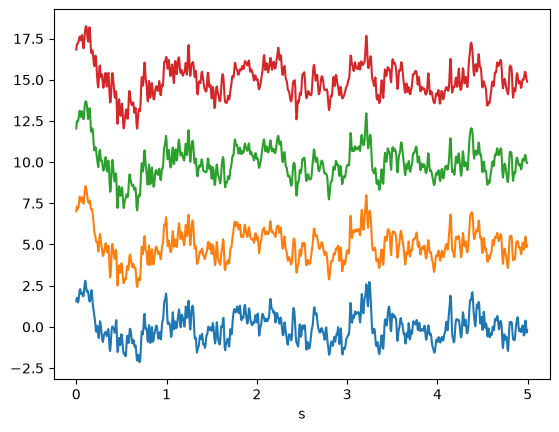

In [11]:
Z = eu.load_subject(1)
print(Z[4].shape, Z[8].shape)                  # (19680, 64) both
print(Z[4].mean().round(3), Z[4].std().round(3))  # 0, 1 exactly
print(Z[8].mean().round(3), Z[8].std().round(3))  # near 0, 1, not exact

t = np.arange(800) / 160
plt.plot(t, Z[8][:800, :4] + np.arange(4) * 5); plt.xlabel("s"); plt.show()


## R^2 and the persistence forecast

In [12]:
for h in fc.HORIZONS:
    print(h, round(fc.evaluate(fc.persistence, Z[8], h), 3))


1 0.869
4 0.23
16 -0.576
32 -1.135


## per-channel AR baseline

In [13]:
P_GRID = (8, 16, 32, 64, 128, 256)
for h in fc.HORIZONS:
    scores = [fc.evaluate(fc.ar_predictor(fc.fit_ar(Z[4], h, p)), Z[8], h) for p in P_GRID]
    print(h, "persist", round(fc.evaluate(fc.persistence, Z[8], h), 3),
          "| AR", {p: round(float(s), 3) for p, s in zip(P_GRID, scores)})


1 persist 0.869 | AR {8: 0.996, 16: 0.999, 32: 1.0, 64: 1.0, 128: 1.0, 256: 1.0}
4 persist 0.23 | AR {8: 0.476, 16: 0.635, 32: 0.656, 64: 0.666, 128: 0.678, 256: 0.684}
16 persist -0.576 | AR {8: 0.068, 16: 0.089, 32: 0.102, 64: 0.141, 128: 0.167, 256: 0.201}
32 persist -1.135 | AR {8: 0.009, 16: 0.024, 32: 0.049, 64: 0.1, 128: 0.136, 256: 0.17}


### now run for 20 subjects and save the results

sanity check that outputs are equal for both fit_ar functions. 

In [14]:
Z = eu.load_subject(1)
# Compare forecasts, not coefficients: the lag matrix is ill-conditioned (cond ~1e5), so the two solvers
# return slightly different coefficients whose forecasts agree to ~1e-7.
r_fast = fc.evaluate(fc.ar_predictor(fc.fit_ar_grid(Z[4], (16, 64))[16, 64]), Z[8], 16)
r_ref = fc.evaluate(fc.ar_predictor(fc.fit_ar(Z[4], 16, 64)), Z[8], 16)
print(r_fast, r_ref, np.isclose(r_fast, r_ref))   # expect True

0.14102956410910317 0.14102956410824885 True


In [ ]:
P_GRID = (16, 32, 64, 128, 256, 512)
SUBJ = keep[:20]
RES_FILE = "results/val_ar.csv"            # run-8 R^2 per (subject, h, method, p)
CFG_FILE = "results/val_ar_config.json"    # settings that produced RES_FILE
FORCE = False                              # True = recompute even if a matching file exists

# If you change the filter in eeg_utils.load_run, update "band" so the cache is invalidated.
CONFIG = dict(subjects=[int(s) for s in SUBJ], p_grid=list(P_GRID), horizons=list(fc.HORIZONS),
              warmup=fc.WARMUP, band="1-40 Hz causal (minimum phase)", runs=dict(train=4, val=8))

cached = (not FORCE and os.path.exists(RES_FILE) and os.path.exists(CFG_FILE)
          and json.load(open(CFG_FILE)) == CONFIG)
if cached:
    res = pd.read_csv(RES_FILE)
    print(f"loaded {RES_FILE} ({len(res)} rows); set FORCE = True to recompute")
else:
    rows = []
    for s in SUBJ:
        Z = eu.load_subject(s)
        coefs = fc.fit_ar_grid(Z[4], P_GRID)
        for h in fc.HORIZONS:
            rows.append(dict(subject=s, h=h, method="persist", p=0,
                             r2=fc.evaluate(fc.persistence, Z[8], h)))
            for p in P_GRID:
                rows.append(dict(subject=s, h=h, method="AR", p=p,
                                 r2=fc.evaluate(fc.ar_predictor(coefs[h, p]), Z[8], h)))
        print(s, end=" ", flush=True)
    res = pd.DataFrame(rows)
    os.makedirs("results", exist_ok=True)
    res.to_csv(RES_FILE, index=False)
    json.dump(CONFIG, open(CFG_FILE, "w"), indent=1)

res[res.method == "AR"].pivot_table(index="p", columns="h", values="r2", aggfunc="mean").round(3)

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 

h,1,4,16,32
p,,,,
16,0.999,0.571,0.122,0.033
32,0.999,0.610,0.134,0.055
64,0.999,0.619,0.160,0.092
128,0.999,0.632,0.190,0.131
256,0.999,0.639,0.218,0.167
512,0.999,0.641,0.232,0.184


## pick p, then bootstrap over subjects

In [16]:
idx = fc.boot_idx(len(SUBJ))   # (10,000, n_subjects), seed fc.SEED; the same draws for every horizon and method -> paired
ar = res[res.method == "AR"]
best_p = ar.groupby(["h", "p"]).r2.mean().groupby("h").idxmax().map(lambda x: x[1])

summary = []
for h in fc.HORIZONS:
    a = ar[(ar.h == h) & (ar.p == best_p[h])].set_index("subject").r2.loc[SUBJ]
    q = res[(res.method == "persist") & (res.h == h)].set_index("subject").r2.loc[SUBJ]
    d = (a - q).values
    ci = lambda v: np.percentile(v[idx].mean(1), [2.5, 97.5]).round(3)
    summary.append(dict(h=h, p=best_p[h],
                        AR=round(a.mean(), 3), AR_CI=ci(a.values),
                        persist=round(q.mean(), 3), persist_CI=ci(q.values),
                        diff=round(d.mean(), 3), diff_CI=ci(d),
                        AR_wins=f"{(d > 0).sum()}/{len(d)}"))
pd.DataFrame(summary)

,h,p,AR,AR_CI,persist,persist_CI,diff,diff_CI,AR_wins
0,1,512,0.999,"[0.999, 1.0]",0.805,"[0.754, 0.851]",0.195,"[0.148, 0.245]",20/20
1,4,512,0.641,"[0.59, 0.693]",0.134,"[-0.002, 0.275]",0.507,"[0.405, 0.61]",20/20
2,16,512,0.232,"[0.205, 0.263]",-0.481,"[-0.56, -0.392]",0.713,"[0.639, 0.773]",20/20
3,32,512,0.184,"[0.157, 0.214]",-1.066,"[-1.135, -0.973]",1.250,"[1.141, 1.337]",20/20
